# Datos aleatoriamente distribuidos

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

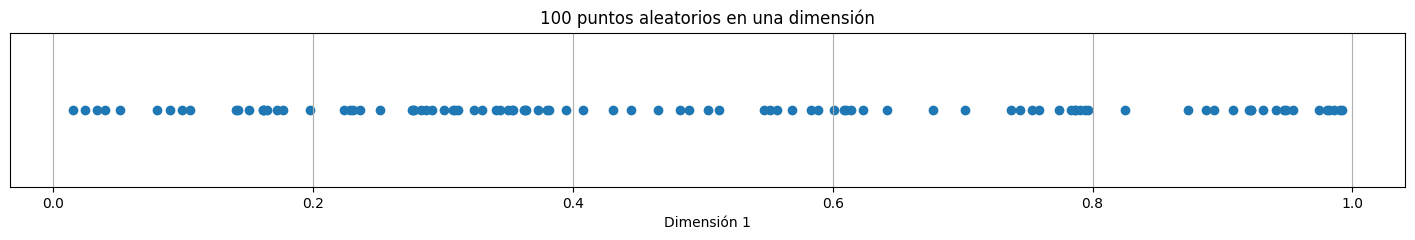

In [ ]:
# Generar 100 puntos aleatorios en una dimensión
x_1d = np.___.___(0, 1, 100)

# Dibujar los puntos
plt.figure(figsize=(18, 2))

#Gráfico de dispersión. La coordenada y es siempre 0
plt.___(x_1d, np.___(x_1d))
plt.title('100 puntos aleatorios en una dimensión')
plt.xlabel('Dimensión 1')

#Marcadores
plt.yticks([])
plt.grid(True)

plt.show()


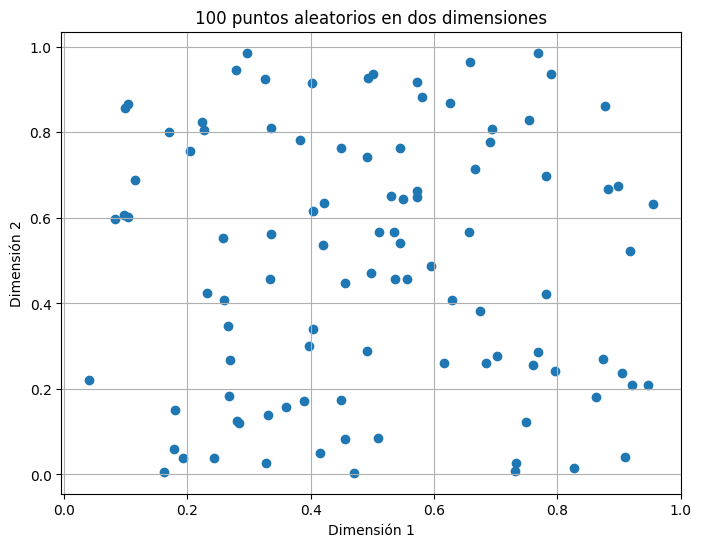

In [ ]:
# Generar 100 puntos aleatorios en dos dimensiones
x = ___
y = ___

# Dibujar los puntos
plt.figure(figsize=(8, 6))
___
plt.title('100 puntos aleatorios en dos dimensiones')
plt.xlabel('Dimensión 1')
plt.ylabel('Dimensión 2')
plt.grid(True)
plt.show()


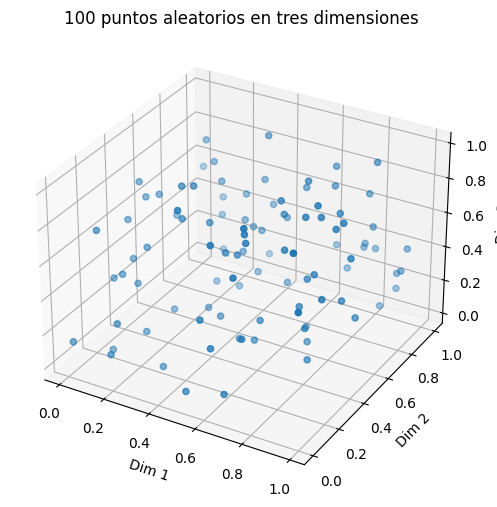

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# Generar 100 puntos aleatorios en tres dimensiones
x_3d = ___
y_3d = ___
z_3d = ___

# Dibujar los puntos
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x_3d, y_3d, z_3d)

ax.set_title('100 puntos aleatorios en tres dimensiones')
ax.set_xlabel('Dim 1')
ax.set_ylabel('Dim 2')
ax.set_zlabel('Dim 3')
plt.show()


# Ejemplo Maldición de la Dimensionalidad

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split



In [ ]:
# Definimos la URL del conjunto de datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Especificamos los nombres de las columnas
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin', 'Car Name']

# Cargamos los datos en un DataFrame de pandas
data = pd.read_csv(url, sep=r'\s+', names=column_names, na_values='?')

# Eliminamos las columnas 'Car Name' y 'Origin' ya que no es relevante para nuestro análisis
data = data.drop('Car Name', axis=1)
data = data.drop('Origin', axis=1)

In [ ]:
#Colocamos la variable objetivo al final
data = data[['Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'MPG']]

# Mostramos las primeras filas del DataFrame
data

,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,MPG
0,8,307.0,130.0,3504.0,12.0,70,18.0
1,8,350.0,165.0,3693.0,11.5,70,15.0
2,8,318.0,150.0,3436.0,11.0,70,18.0
3,8,304.0,150.0,3433.0,12.0,70,16.0
4,8,302.0,140.0,3449.0,10.5,70,17.0
...,...,...,...,...,...,...,...
393,4,140.0,86.0,2790.0,15.6,82,27.0
394,4,97.0,52.0,2130.0,24.6,82,44.0
395,4,135.0,84.0,2295.0,11.6,82,32.0
396,4,120.0,79.0,2625.0,18.6,82,28.0


In [ ]:
#Eliminamos datos faltantes
data = data.dropna()

## Predicción con una variable

In [ ]:
# Variables predictoras
predictors = ['Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year']

# Dividimos los datos en conjuntos de entrenamiento y prueba
X = data[predictors]
y = data['MPG']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Diccionario para almacenar los errores
mse_values = {}

# Entrenar un modelo para cada variable predictora y calcular el MSE
for predictor in predictors:

    # limitamos el conjunto de datos a una sola variable predictora (predictor)
    X_train_single = X_train[[predictor]]
    X_test_single = X_test[[predictor]]

    # Ajustamos un modelo de regresión lineal
    model = LinearRegression()
    model.fit(X_train_single, y_train)

    # Generamos predicciones
    y_pred = model.predict(X_test_single)
    mse = mean_squared_error(y_test, y_pred)

    #almacenamos el valor
    mse_values[predictor] = mse

# Mostrar los MSEs
for predictor, mse in mse_values.items():
    print(f"MSE utilizando {predictor}: {mse:.2f}")

# Identificar la variable con el menor MSE
min_mse_predictor = min(mse_values, key=mse_values.get)
print(f"\nLa variable que produce el menor MSE es: {min_mse_predictor} con un MSE de {mse_values[min_mse_predictor]:.2f}")

MSE utilizando Cylinders: 22.10
MSE utilizando Displacement: 19.91
MSE utilizando Horsepower: 22.03
MSE utilizando Weight: 19.98
MSE utilizando Acceleration: 47.85
MSE utilizando Model Year: 40.72

La variable que produce el menor MSE es: Displacement con un MSE de 19.91


# Predicción con varias variables

Ahora vamos a elegir conjuntos de variables de diferente tamaño

In [ ]:
from itertools import combinations

In [ ]:
list(combinations(predictors, 4))

[('Cylinders', 'Displacement', 'Horsepower', 'Weight'),
 ('Cylinders', 'Displacement', 'Horsepower', 'Acceleration'),
 ('Cylinders', 'Displacement', 'Horsepower', 'Model Year'),
 ('Cylinders', 'Displacement', 'Weight', 'Acceleration'),
 ('Cylinders', 'Displacement', 'Weight', 'Model Year'),
 ('Cylinders', 'Displacement', 'Acceleration', 'Model Year'),
 ('Cylinders', 'Horsepower', 'Weight', 'Acceleration'),
 ('Cylinders', 'Horsepower', 'Weight', 'Model Year'),
 ('Cylinders', 'Horsepower', 'Acceleration', 'Model Year'),
 ('Cylinders', 'Weight', 'Acceleration', 'Model Year'),
 ('Displacement', 'Horsepower', 'Weight', 'Acceleration'),
 ('Displacement', 'Horsepower', 'Weight', 'Model Year'),
 ('Displacement', 'Horsepower', 'Acceleration', 'Model Year'),
 ('Displacement', 'Weight', 'Acceleration', 'Model Year'),
 ('Horsepower', 'Weight', 'Acceleration', 'Model Year')]

In [ ]:
#AHORA VAMOS A ANALIZAR LA EVOLUCIÓN AL IR AÑADIENDO MÁS VARIABLES

# Diccionario para almacenar los MSE medios
mse_medios = {}

# Realizamos 5 divisiones distintas de entrenamiento y test
num_divisiones = 5

#Iteramos sobre todos los posibles tamaños del conjunto de variables.
for num_vars in range(1, len(predictors) + 1):
    combinaciones = list(combinations(predictors, num_vars))
    mse_total = 0

    # Realizar cinco divisiones diferentes de entrenamiento y prueba
    for seed in range(num_divisiones):
        X_train, X_test, y_train, y_test = train_test_split(X[predictors], y, test_size=0.2, random_state=seed)

        for combinacion in combinaciones:

            # Seleccionamos los datos de acuerdo a la combinación actual
            X_train_comb = X_train[list(combinacion)]
            X_test_comb = X_test[list(combinacion)]

            # Ajustamos un modelo de regresión.
            model = LinearRegression()
            model.fit(X_train_comb,y_train)

            # Obtenemos las predicciones
            y_pred = model.predict(X_test_comb)
            mse = mean_squared_error(y_test,y_pred)

            #almacenamos
            mse_total += mse

    # Calcular el MSE medio para esta cantidad de variables predictoras
    mse_medio = mse_total / (len(combinaciones) * num_divisiones)  # Dividir por el número total de modelos entrenados
    mse_medios[num_vars] = mse_medio
    print(f"MSE medio con {num_vars} variables predictoras: {mse_medio:.2f}")




MSE medio con 1 variables predictoras: 29.76
MSE medio con 2 variables predictoras: 20.07
MSE medio con 3 variables predictoras: 16.68
MSE medio con 4 variables predictoras: 14.95
MSE medio con 5 variables predictoras: 13.46
MSE medio con 6 variables predictoras: 11.97


In [ ]:
# Comparar MSE medios para ver la disminución porcentual

# Creamos un diccionario para monitorizar la evolución y
# luego representarla gráficamente.
disminucion_mse_regresion = {}

for num_vars in range(2, len(predictors) + 1):
    disminucion_mse = ((mse_medios[num_vars - 1] - mse_medios[num_vars]) / mse_medios[num_vars - 1]) * 100
    print(f"Mejora porcentual del MSE medio al pasar de {num_vars - 1} a {num_vars} variables predictoras: {disminucion_mse:.2f}%")

    #Lo almacenamos para la representación gráfica
    disminucion_mse = ((mse_medios[num_vars - 1] - mse_medios[num_vars]) / mse_medios[num_vars - 1]) * 100
    disminucion_mse_regresion[num_vars] = disminucion_mse

Mejora porcentual del MSE medio al pasar de 1 a 2 variables predictoras: 32.56%
Mejora porcentual del MSE medio al pasar de 2 a 3 variables predictoras: 16.91%
Mejora porcentual del MSE medio al pasar de 3 a 4 variables predictoras: 10.39%
Mejora porcentual del MSE medio al pasar de 4 a 5 variables predictoras: 9.96%
Mejora porcentual del MSE medio al pasar de 5 a 6 variables predictoras: 11.02%


# Predicción con varias variables con primeros vecinos

Repetimos el proceso con el método de los primeros vecinos.

In [ ]:
from sklearn.neighbors import ___

# Diccionario para almacenar los MSE medios
mse_medios_knn = {}

# Realizamos 5 divisiones distintas de entrenamiento y test
num_divisiones = 5


for num_vars in range(___)
    combinaciones = list(combinations(predictors, num_vars))
    mse_total = 0

    # Realizar cinco divisiones diferentes de entrenamiento y prueba
    for seed in range(___):
        X_train, X_test, y_train, y_test = ___(___, y, test_size=0.2, random_state=seed)

        for combinacion in combinaciones:
            X_train_comb = ___
            X_test_comb = ___

            # Usar KNN con k=4 en lugar de regresión lineal
            model = ___
            ___

            # Predicciones y error
            y_pred = ___
            mse = ___

            #Almacenamos los errores
            mse_total += mse

    # Calcular el MSE medio para esta cantidad de variables predictoras
    mse_medio = mse_total / (len(combinaciones) * num_divisiones)  # Dividir por el número total de modelos entrenados
    mse_medios_knn[num_vars] = mse_medio
    print(f"MSE medio con KNN (k=4) y {num_vars} variables predictoras: {mse_medio:.2f}")

MSE medio con KNN (k=4) y 1 variables predictoras: 29.81
MSE medio con KNN (k=4) y 2 variables predictoras: 19.45
MSE medio con KNN (k=4) y 3 variables predictoras: 16.47
MSE medio con KNN (k=4) y 4 variables predictoras: 16.12
MSE medio con KNN (k=4) y 5 variables predictoras: 16.57
MSE medio con KNN (k=4) y 6 variables predictoras: 17.16


In [ ]:

# Creamos un diccionario para monitorizar la evolución.
disminucion_mse_knn = {}

# (Opcional) Comparar MSE medios para ver la disminución procentual
for num_vars in range(2, len(predictors) + 1):
    disminucion_mse = ((mse_medios_knn[num_vars - 1] - mse_medios_knn[num_vars]) / mse_medios_knn[num_vars - 1]) * 100
    print(f"Mejora porcentual del MSE medio al pasar de {num_vars - 1} a {num_vars} variables predictoras con KNN (k=4): {disminucion_mse:.2f}%")

    #Almacenamos los valores para el gráfico
    disminucion_mse = ((mse_medios_knn[num_vars - 1] - mse_medios_knn[num_vars]) / mse_medios_knn[num_vars - 1]) * 100
    disminucion_mse_knn[num_vars] = disminucion_mse

Mejora porcentual del MSE medio al pasar de 1 a 2 variables predictoras con KNN (k=4): 34.74%
Mejora porcentual del MSE medio al pasar de 2 a 3 variables predictoras con KNN (k=4): 15.33%
Mejora porcentual del MSE medio al pasar de 3 a 4 variables predictoras con KNN (k=4): 2.09%
Mejora porcentual del MSE medio al pasar de 4 a 5 variables predictoras con KNN (k=4): -2.78%
Mejora porcentual del MSE medio al pasar de 5 a 6 variables predictoras con KNN (k=4): -3.56%


# Representamos Gráficamente la evolución del MSE en cada caso

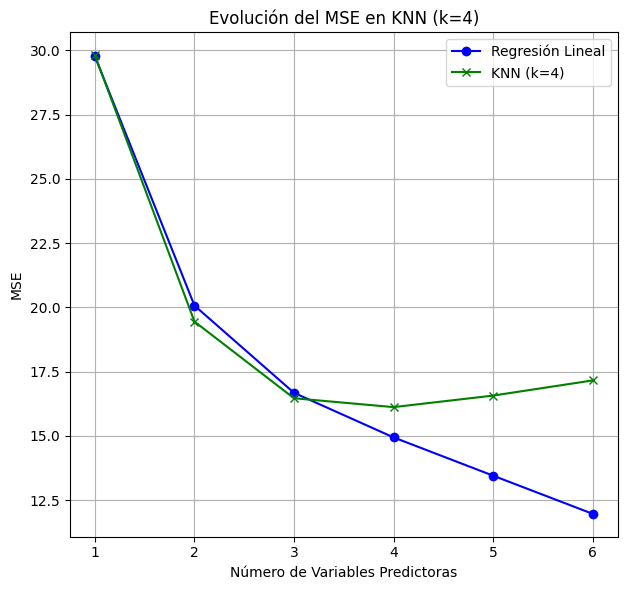

In [ ]:
# Extraer valores para el gráfico
num_variables_mse = list(mse_medios.keys())
mse_regresion = list(mse_medios.values())
mse_knn = list(mse_medios_knn.values())

# Crear gráfico para la regresión lineal
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)  # Primer subgráfico
plt.plot(num_variables_mse, mse_regresion, label='Regresión Lineal', marker='o', color='blue')
plt.xlabel('Número de Variables Predictoras')
plt.ylabel('MSE')
plt.title('Evolución del MSE en Regresión Lineal')
plt.legend()
plt.grid(True)

# Crear gráfico para KNN
# plt.subplot(1, 2, 2)  # Segundo subgráfico
plt.plot(num_variables_mse, mse_knn, label='KNN (k=4)', marker='x', color='green')
plt.xlabel('Número de Variables Predictoras')
plt.ylabel('MSE')
plt.title('Evolución del MSE en KNN (k=4)')
plt.legend()
plt.grid(True)

# Mostrar los gráficos
plt.tight_layout()
plt.show()



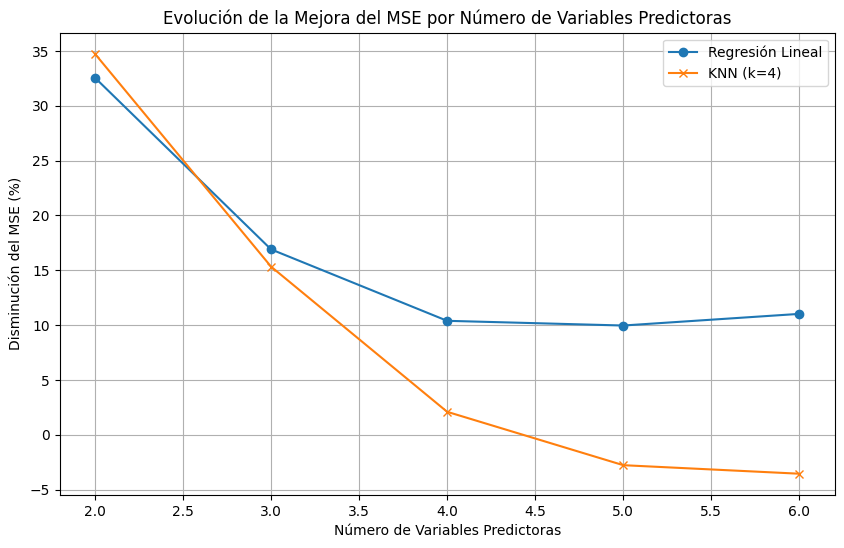

In [ ]:
#REPRESENTAMOS LA EVOLUCIÓN DE LA MEJORA

# Extraer valores para el gráfico
num_variables = list(disminucion_mse_regresion.keys())
disminucion_regresion = list(disminucion_mse_regresion.values())
disminucion_knn = list(disminucion_mse_knn.values())

# Crear gráfico
plt.figure(figsize=(10, 6))
plt.plot(num_variables, disminucion_regresion, label='Regresión Lineal', marker='o')
plt.plot(num_variables, disminucion_knn, label='KNN (k=4)', marker='x')

# Añadir etiquetas y título
plt.xlabel('Número de Variables Predictoras')
plt.ylabel('Disminución del MSE (%)')
plt.title('Evolución de la Mejora del MSE por Número de Variables Predictoras')
plt.legend()
plt.grid(True)
plt.show()
